In [30]:
import numpy as np
import pandas as pd
from sklearn import metrics

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

import spacy

# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

In [31]:
df=pd.read_csv(Path.cwd()/'data'/ 'guardian_news_subset.csv')

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id                  2500 non-null   int64
 1   webTitle            2500 non-null   str  
 2   bodyContent         2483 non-null   str  
 3   webPublicationDate  2500 non-null   str  
dtypes: int64(1), str(3)
memory usage: 78.3 KB


In [33]:
df.fillna(' ',inplace=True)

,id,webTitle,bodyContent,webPublicationDate
0,17349,John Prine review – legendary songwriter looks...,John Prine walked onstage around 10.40pm Thurs...,2016-09-24T19:05:52Z
1,17858,Nigel Kennedy; Oxford lieder festival; London ...,"Identity and dispossession cast long shadows, ...",2016-10-30T07:30:02Z
2,60943,The week in classical: BBC Proms 49 & 51; Lond...,We are a timorous nation when presented with “...,2018-08-26T07:00:07Z
3,118230,"Archie Shepp on jazz, race and freedom: 'Insti...",One night at Five Spot Cafe in the early 1960s...,2021-02-24T13:00:18Z
4,21992,'He was my inspiration': fans flock to George ...,George Michael fans have flocked to Highgate i...,2016-12-27T18:07:27Z
...,...,...,...,...
2495,71937,Tip a great beach cafe or bar in Europe for a ...,We want to hear about lovely beachside cafes a...,2019-02-26T12:16:52Z
2496,18074,A foodie tour of Iran: it's poetry on a plate,"Imagine a verdant, landscape filled with rice ...",2016-10-29T06:00:12Z
2497,85082,"Elmley Nature Reserve, Kent: a peaceful retrea...","Beyond the glass wall of the shepherd’s hut, a...",2019-09-29T10:00:41Z
2498,39300,UK holidaymakers set to pay for making Spain t...,With a record 18 million people visiting last ...,2017-09-28T05:30:30Z


In [34]:
# id nam nece pomoci u klasterizaciju zato to odmah mozemo da odmacimo .
# pubblication date nije relevatann po trekstu zadatak
#Spajamo 2 kolone

#webTitle i bodyContent
df['articleText']= df['webTitle']+df['bodyContent']


In [35]:
df

,id,webTitle,bodyContent,webPublicationDate,articleText
0,17349,John Prine review – legendary songwriter looks...,John Prine walked onstage around 10.40pm Thurs...,2016-09-24T19:05:52Z,John Prine review – legendary songwriter looks...
1,17858,Nigel Kennedy; Oxford lieder festival; London ...,"Identity and dispossession cast long shadows, ...",2016-10-30T07:30:02Z,Nigel Kennedy; Oxford lieder festival; London ...
2,60943,The week in classical: BBC Proms 49 & 51; Lond...,We are a timorous nation when presented with “...,2018-08-26T07:00:07Z,The week in classical: BBC Proms 49 & 51; Lond...
3,118230,"Archie Shepp on jazz, race and freedom: 'Insti...",One night at Five Spot Cafe in the early 1960s...,2021-02-24T13:00:18Z,"Archie Shepp on jazz, race and freedom: 'Insti..."
4,21992,'He was my inspiration': fans flock to George ...,George Michael fans have flocked to Highgate i...,2016-12-27T18:07:27Z,'He was my inspiration': fans flock to George ...
...,...,...,...,...,...
2495,71937,Tip a great beach cafe or bar in Europe for a ...,We want to hear about lovely beachside cafes a...,2019-02-26T12:16:52Z,Tip a great beach cafe or bar in Europe for a ...
2496,18074,A foodie tour of Iran: it's poetry on a plate,"Imagine a verdant, landscape filled with rice ...",2016-10-29T06:00:12Z,A foodie tour of Iran: it's poetry on a plateI...
2497,85082,"Elmley Nature Reserve, Kent: a peaceful retrea...","Beyond the glass wall of the shepherd’s hut, a...",2019-09-29T10:00:41Z,"Elmley Nature Reserve, Kent: a peaceful retrea..."
2498,39300,UK holidaymakers set to pay for making Spain t...,With a record 18 million people visiting last ...,2017-09-28T05:30:30Z,UK holidaymakers set to pay for making Spain t...


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id                  2500 non-null   int64
 1   webTitle            2500 non-null   str  
 2   bodyContent         2500 non-null   str  
 3   webPublicationDate  2500 non-null   str  
 4   articleText         2500 non-null   str  
dtypes: int64(1), str(4)
memory usage: 97.8 KB


In [37]:
#vektor reci uz spacy medium model
nlp_pipe=spacy.load("en_core_web_md",disable=['parser','ner'])

In [43]:
df['articleText_lenght']=df.articleText.str.split().str.len()

In [45]:
df.articleText_lenght.describe()

count    2500.00000
mean      797.33360
std       570.98567
min         5.00000
25%       438.75000
50%       695.00000
75%       984.00000
max      7276.00000
Name: articleText, dtype: float64

In [ ]:
# da bi brze radilo mogli smo da skratimo ... claude da li je bitno da smo ovde skratili kada radimo sa vecotirma reci odgovori mi ...

In [38]:
def srediTekst(doc):
    ocisceniTokeni=[]
    tokens=nlp_pipe(doc)
    for token in tokens:
        lemma_lower=token.lemma_.lower()
        if token.is_stop and token not in['no','not'] :
            continue
        if token.is_space or token.is_punct or token.like_url or token.like_num:
            continue
        ocisceniTokeni.append(lemma_lower)
    return ocisceniTokeni

In [41]:
vektori=[]
for tekst in df.articleText:
    reci=srediTekst(tekst)
    vektori.append(nlp_pipe(" ".join(reci)).vector)

In [46]:
vektori=np.array(vektori)
print(vektori.shape)

(2500, 300)


In [47]:
# Izvršiti klasterizaciju (transformisanih) novinskih tekstova primenom aglomerativnog hijerarhijskog klasterovanja.
# Odrediti optimalni broj klastera na osnovu dendrograma i siluet skora (silhouette score).
# Obrazložiti izbor optimalnog broja klastera.
from scipy.spatial.distance import pdist # OVO MROA DA SE ZNA NAPAMET CLAUDE ZABELIZI OVAJ IMPRORT

ward_linkage=sch.linkage(pdist(vektori,metric='cosine'),method='ward')


{'icoord': [[25.0, 25.0, 35.0, 35.0],
  [15.0, 15.0, 30.0, 30.0],
  [5.0, 5.0, 22.5, 22.5],
  [55.0, 55.0, 65.0, 65.0],
  [115.0, 115.0, 125.0, 125.0],
  [105.0, 105.0, 120.0, 120.0],
  [95.0, 95.0, 112.5, 112.5],
  [85.0, 85.0, 103.75, 103.75],
  [75.0, 75.0, 94.375, 94.375],
  [165.0, 165.0, 175.0, 175.0],
  [155.0, 155.0, 170.0, 170.0],
  [145.0, 145.0, 162.5, 162.5],
  [135.0, 135.0, 153.75, 153.75],
  [84.6875, 84.6875, 144.375, 144.375],
  [60.0, 60.0, 114.53125, 114.53125],
  [185.0, 185.0, 195.0, 195.0],
  [225.0, 225.0, 235.0, 235.0],
  [215.0, 215.0, 230.0, 230.0],
  [205.0, 205.0, 222.5, 222.5],
  [190.0, 190.0, 213.75, 213.75],
  [245.0, 245.0, 255.0, 255.0],
  [275.0, 275.0, 285.0, 285.0],
  [265.0, 265.0, 280.0, 280.0],
  [250.0, 250.0, 272.5, 272.5],
  [201.875, 201.875, 261.25, 261.25],
  [295.0, 295.0, 305.0, 305.0],
  [355.0, 355.0, 365.0, 365.0],
  [345.0, 345.0, 360.0, 360.0],
  [335.0, 335.0, 352.5, 352.5],
  [325.0, 325.0, 343.75, 343.75],
  [315.0, 315.0, 334.375

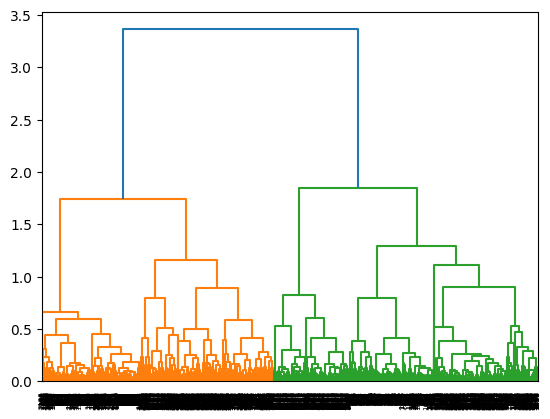

In [48]:
sch.dendrogram(ward_linkage)

In [49]:
# vidimo da je optimalan broj klastera od 3 do 8
#Siluete provera

cos_dist=1-cosine_similarity(vektori)
dist_clipped=np.clip(cos_dist,0,None)
for k in range(3,9):
    klasteri=sch.fcluster(ward_linkage,t=k,criterion='maxclust')
    print(k,round(silhouette_score(dist_clipped,klasteri,metric='precomputed'),4))

3 0.2144
4 0.1741
5 0.1704
6 0.1761
7 0.1752
8 0.148


In [ ]:
# po siluete score optimalno je 3 klastera

In [ ]:
N_CLUSTERS = 3


In [50]:
df['clust']=sch.fcluster(ward_linkage,t=3,criterion='maxclust')
print(df.clust.value_counts())

clust
1    1170
3     949
2     381
Name: count, dtype: int64


In [ ]:
# prvi klaster ima 1170 obzervacija, drugi 949 treci 381...

In [54]:
keyword_extractor=TfidfVectorizer(tokenizer=srediTekst,token_pattern=None,min_df=0.01,max_df=0.95,ngram_range=(1,2))

In [55]:
#Za svaki od klastera odrediti top 10 reči / izraza na osnovu TF-IDF metrike.
def get_keywords_from_clust(cluster):
    tekst=df[df['clust']==cluster].articleText
    tfidf=keyword_extractor.fit_transform(tekst)
    proseci=tfidf.mean(axis=0).A1
    reci=keyword_extractor.get_feature_names_out()
    rezultat=pd.Series(proseci,index=reci)
    return rezultat.nlargest(10).items()

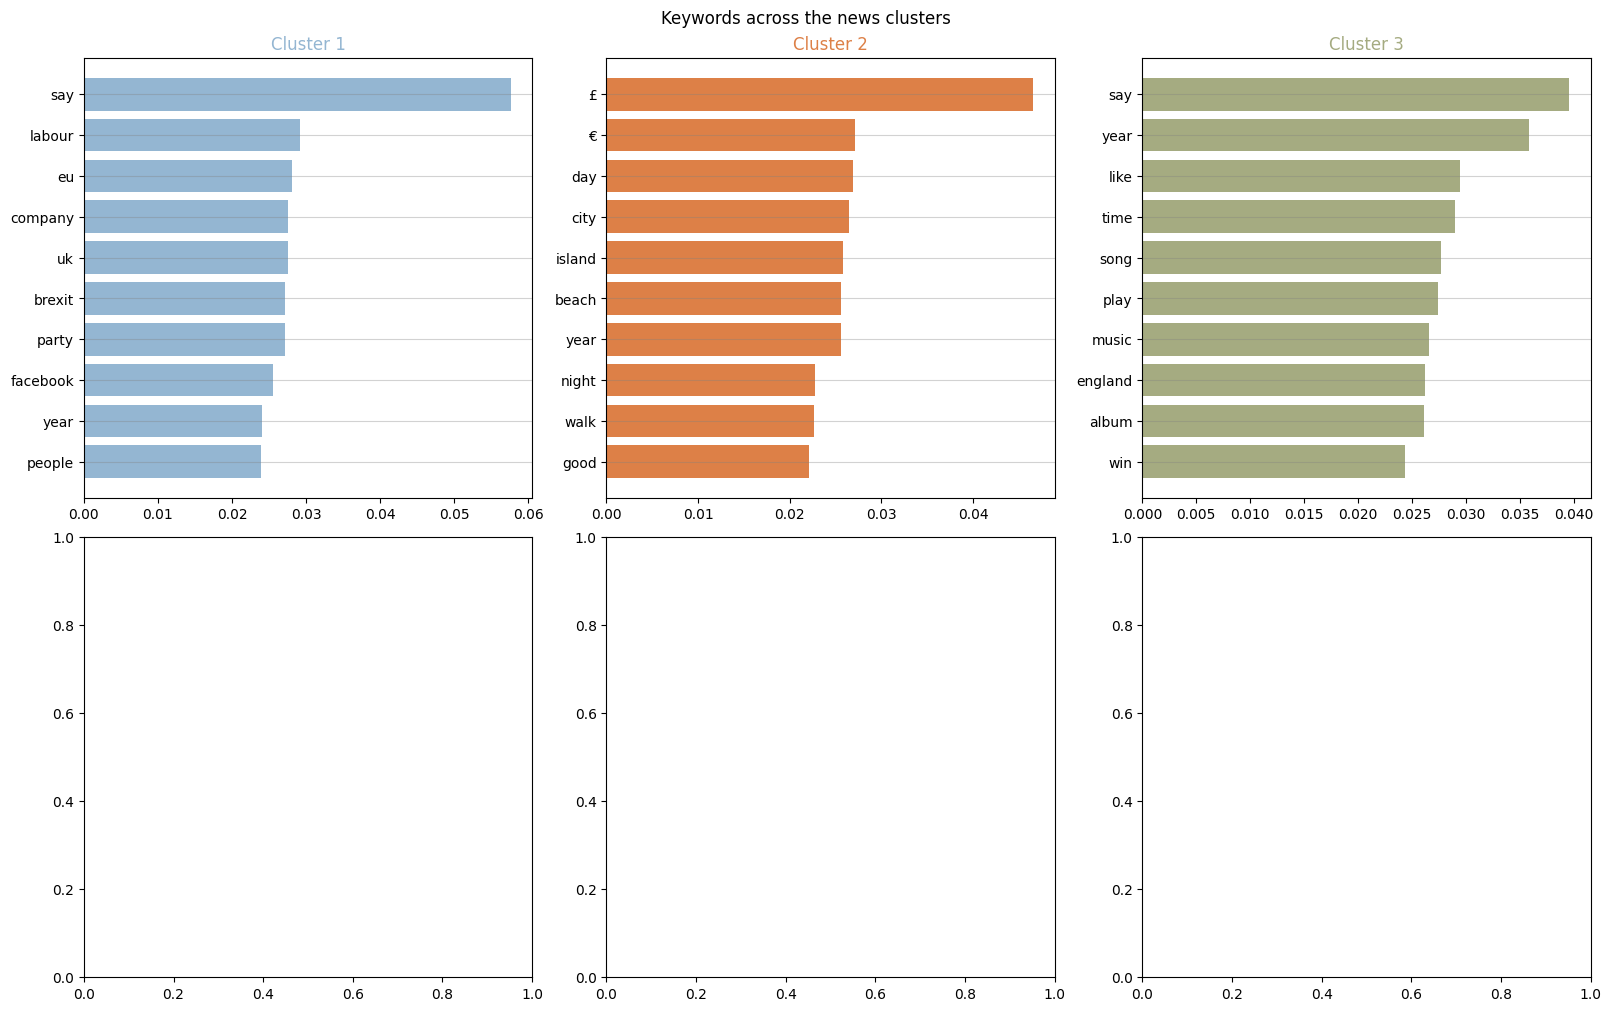

In [56]:
from pypalettes import load_cmap

fig, ax_grid = plt.subplots(nrows=2, ncols=3, figsize=(16, 10), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = df['clust'].nunique()
for i in range(n_clust):

    scored_kwds = get_keywords_from_clust(i+1)
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i+1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)



fig.suptitle("Keywords across the news clusters")

plt.show()

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id                  2500 non-null   int64
 1   webTitle            2500 non-null   str  
 2   bodyContent         2500 non-null   str  
 3   webPublicationDate  2500 non-null   str  
 4   articleText         2500 non-null   str  
 5   articleText_lenght  2500 non-null   int64
 6   clust               2500 non-null   int32
dtypes: int32(1), int64(2), str(4)
memory usage: 127.1 KB


In [62]:
print(df.groupby('clust')[['webTitle','clust']].sample(n=5,random_state=1))

                                               webTitle  clust
947   ‘Twisted priorities’: SNP criticises Sunak's s...      1
1617  Australia’s competition watchdog wants to redu...      1
552   Chequers dinner could end in murder on the Bre...      1
1530  'Bias deep inside the code': the problem with ...      1
1692  Google: Pixel 2 XL screen burn 'should not aff...      1
303   The pint-sized 'singing ambassadors' leading t...      2
2243               10 of the UK’s best new distilleries      2
2211                 10 of the best beach bars in Spain      2
2369  Bring on Valhalla: on the Viking trail in Denmark      2
2081              10 island adventures off the UK coast      2
1124  ‘You expect me to shake his hand?’ – Verstappe...      3
269   Mark E Smith: an autodidact fired by a singula...      3
1067  First Flow beats Politologue to claim emphatic...      3
392   Bono tells of his secret half-brother and of f...      3
1262  Victory encouraging but it's Cummins coming of...